In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
#############################################
def denormalize(data, max_value):
    return data * max_value
#############################################



In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, GRU, SimpleRNN
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.optimizers import Adam
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import mean_absolute_error
from keras.layers import Dropout
import random
# Step 1: Load the necessary data
max_agg = np.loadtxt("/content/drive/MyDrive/Colab Notebooks/deep Learning/WaterHeatermaxAgg.txt")
max_agg = max_agg/1000
max_app = np.loadtxt("/content/drive/MyDrive/Colab Notebooks/deep Learning/WaterHeatermaxApp.txt")
max_app = max_app/1000
input_data = np.loadtxt("/content/drive/MyDrive/Colab Notebooks/deep Learning/Input_Data.txt", delimiter=",")

output_data = np.loadtxt("/content/drive/MyDrive/Colab Notebooks/deep Learning/Output_Data.txt", delimiter=",")


seq_length = 120
input_dim = 1
output_dim = 1
num_samples = len(input_data)



# Step 3: Preprocess the data
input_data_norm = input_data / max_agg
output_data_norm = output_data / max_app

# Split the dataset into train and test sets
train_size = int(0.8 * len(input_data_norm))
train_input = input_data_norm[:train_size]
train_output = output_data_norm[:train_size]
test_input = input_data_norm[train_size:]
test_output = output_data_norm[train_size:]







In [4]:
test_output.shape

(10000, 120)

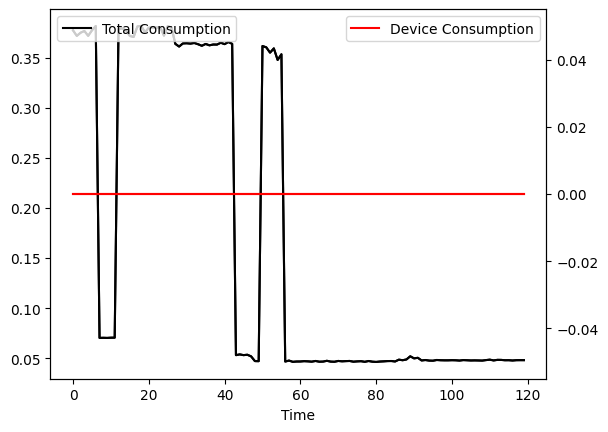

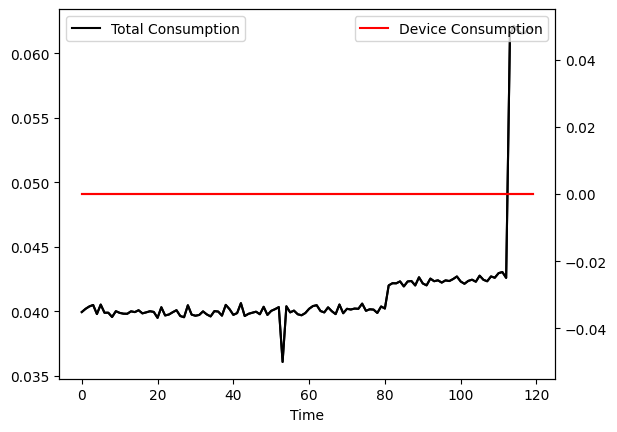

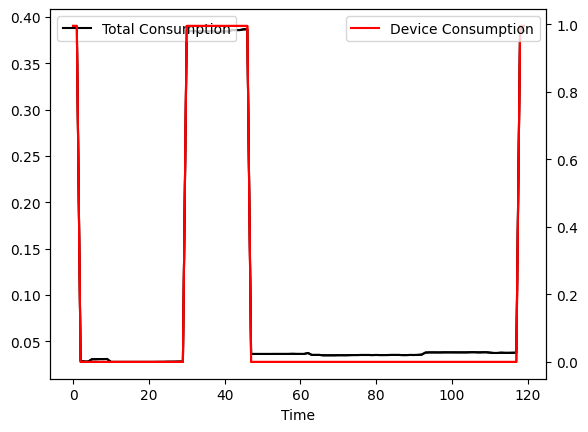

In [5]:

# Visualize data
def plot(total_consumption, device_consumption):
    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()
    ax1.plot(total_consumption, 'k-', label='Total Consumption')
    ax2.plot(device_consumption, 'r-', label='Device Consumption')
    ax1.set_xlabel('Time')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')
    ax1.plot(total_consumption, 'k-', label='Total Consumption')
    ax2.plot(device_consumption, 'r-', label='Device Consumption')
    plt.show()

random_time = np.random.choice(input_data.shape[0], 3, replace=False)
for time in random_time:
    total_consumption = input_data[time]
    device_consumption = output_data[time]
    plot(total_consumption, device_consumption)

In [6]:

mod1 = Sequential()
mod1.add(LSTM(64, input_shape=(120,1), return_sequences=False))
mod1.add(Dropout(0.3))
mod1.add(Dense(120, activation='relu' ))
mod1.compile(loss='mean_squared_error', optimizer='adam')
mod1.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 64)                16896     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 120)               7800      
                                                                 
Total params: 24,696
Trainable params: 24,696
Non-trainable params: 0
_________________________________________________________________


In [7]:
models = [
    Sequential([
        LSTM(64, input_shape=(seq_length, input_dim), return_sequences=True),
        Dense(124, activation='relu'),
        Dropout(0.3),
        Dense(output_dim, activation='relu')
    ]),
    Sequential([
        SimpleRNN(64, input_shape=(seq_length, input_dim), return_sequences=True),
        Dense(124, activation='relu'),
        Dropout(0.3),
        Dense(output_dim, activation='relu')
    ]),
    Sequential([
        GRU(64, input_shape=(seq_length, input_dim), return_sequences=True),
        Dense(124, activation='relu'),
        Dropout(0.3),
        Dense(output_dim, activation='relu')
    ])
]


histories = []  # List to store the history objects

for model in models:
    model.compile(optimizer=Adam(), loss=MeanSquaredError())
    early_stopping = EarlyStopping(monitor='val_loss', patience=5)
    model.summary()
    history = model.fit(train_input, train_output, epochs=50,  validation_split=0.2, callbacks=[early_stopping])
    histories.append(history)  # Append the history object to the list


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 120, 64)           16896     
                                                                 
 dense_1 (Dense)             (None, 120, 124)          8060      
                                                                 
 dropout_1 (Dropout)         (None, 120, 124)          0         
                                                                 
 dense_2 (Dense)             (None, 120, 1)            125       
                                                                 
Total params: 25,081
Trainable params: 25,081
Non-trainable params: 0
_________________________________________________________________
Epoch 1/50
1000/1000 [==============================] - 16s 8ms/step - loss: 0.0147 - val_loss: 0.0133
Epoch 2/50
1000/1000 [==============================] - 8s 8ms/step - loss: 0.0

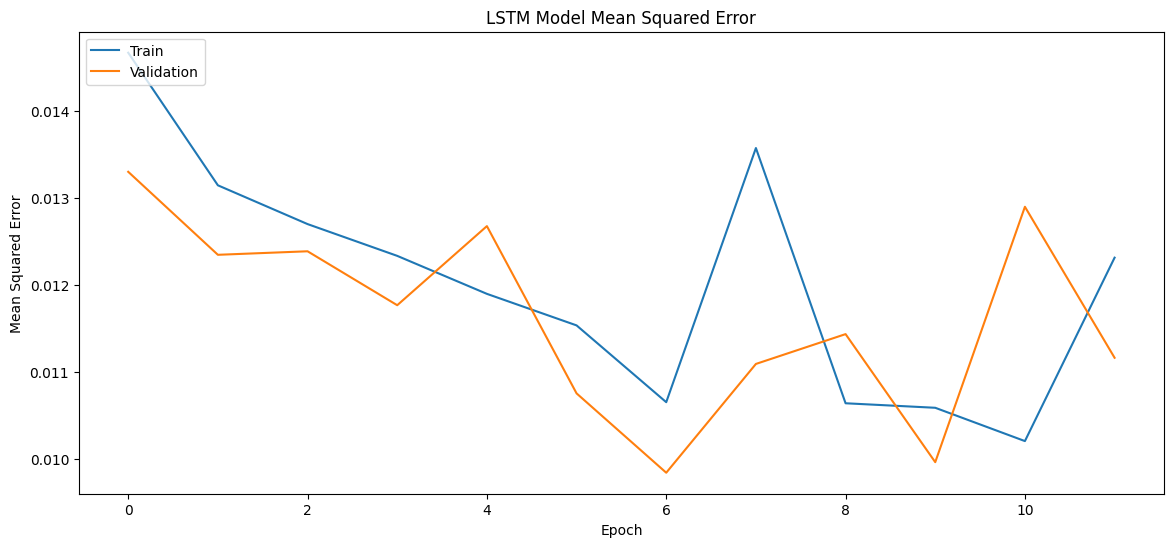

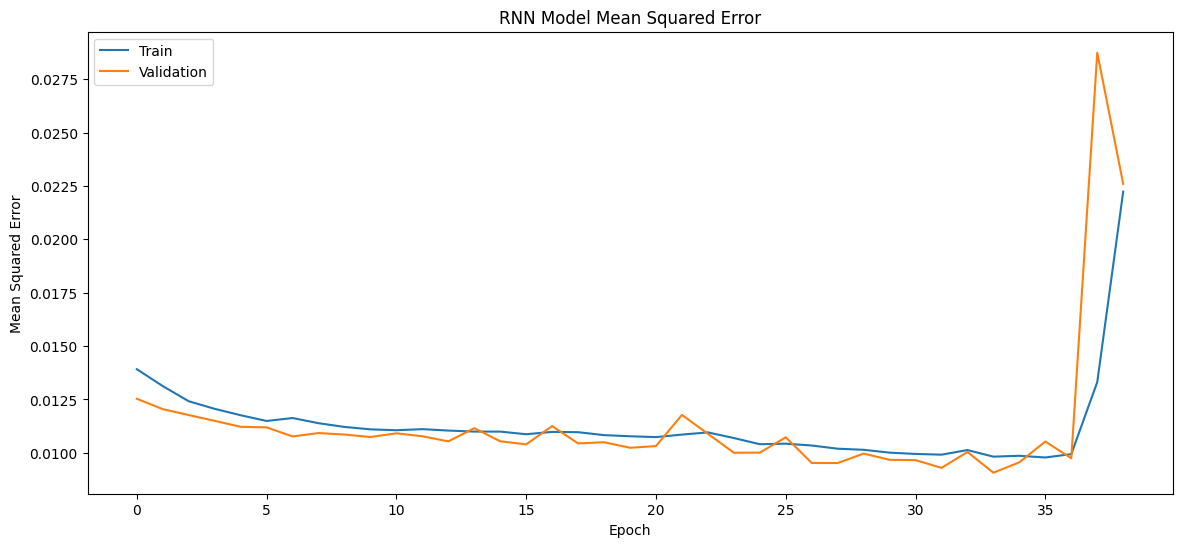

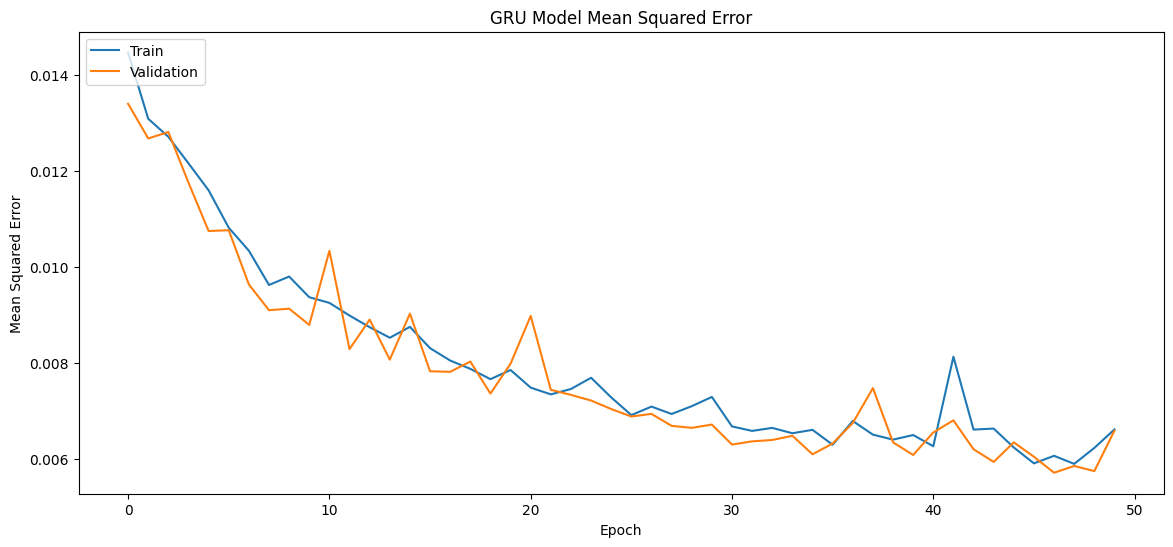

In [8]:
# Plot the history performance scores for each model
for i, history in enumerate(histories):
    labels = ['LSTM', 'RNN', 'GRU']
    plt.figure(figsize=(14, 6))
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{labels[i]} Model Mean Squared Error')
    plt.ylabel('Mean Squared Error')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.savefig(f'{labels[i]}_model_plot.png')  # Save the figure with a unique name
    plt.show()


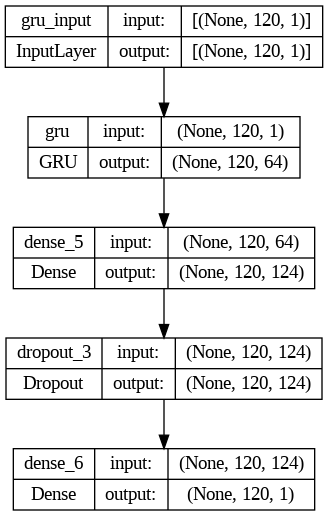

In [9]:
!pip install graphviz
!pip install pydot
from keras.utils.vis_utils import plot_model

# Visualize the LSTM model
plot_model(models[0], to_file='lstm_model.png', show_shapes=True, show_layer_names=True)

# Visualize the SimpleRNN model
plot_model(models[1], to_file='simplernn_model.png', show_shapes=True, show_layer_names=True)

# Visualize the GRU model
plot_model(models[2], to_file='gru_model.png', show_shapes=True, show_layer_names=True)








In [10]:
#############################################
def denormalize(data, max_value):
    return (data * max_value)
#############################################

train_predictions = []
test_predictions = []
for model in models:
    train_predictions.append(denormalize(model.predict(train_input), max_app))
    test_predictions.append(denormalize(model.predict(test_input), max_app))           #denormalise predictions

train_predictions_np = np.array(train_predictions)
test_predictions_np = np.array(test_predictions)
test_predictions_np.shape

313/313 [==============================] - 2s 4ms/step


(3, 10000, 120, 1)

In [11]:

train_rmse = []
train_mae = []
train_max_error = []

test_rmse = []
test_mae = []
test_max_error = []

for i, model in enumerate(models):
    model_train_predictions = train_predictions_np[i].reshape(40000, 120)  # Get predictions for current model
    model_train_rmse = np.sqrt(mean_squared_error(denormalize(train_output, max_app), model_train_predictions))
    model_train_mae = mean_absolute_error(denormalize(train_output, max_app), model_train_predictions)                    #denormalise input-output training set
    model_train_max_error = np.amax(np.abs(denormalize(train_output, max_app) - model_train_predictions))

    train_rmse.append(model_train_rmse)
    train_mae.append(model_train_mae)
    train_max_error.append(model_train_max_error)

for i, model in enumerate(models):
    model_test_predictions = test_predictions_np[i].reshape(10000, 120)  # Get predictions for current model
    model_test_rmse = np.sqrt(mean_squared_error(denormalize(test_output, max_app), model_test_predictions))                #denormalise input-output test set
    model_test_mae = mean_absolute_error(denormalize(test_output, max_app), model_test_predictions)
    model_test_max_error = np.amax(np.abs(denormalize(test_output, max_app) - model_test_predictions))

    test_rmse.append(model_test_rmse)
    test_mae.append(model_test_mae)
    test_max_error.append(model_test_max_error)


In [12]:
train_predictions_np.shape

(3, 40000, 120, 1)

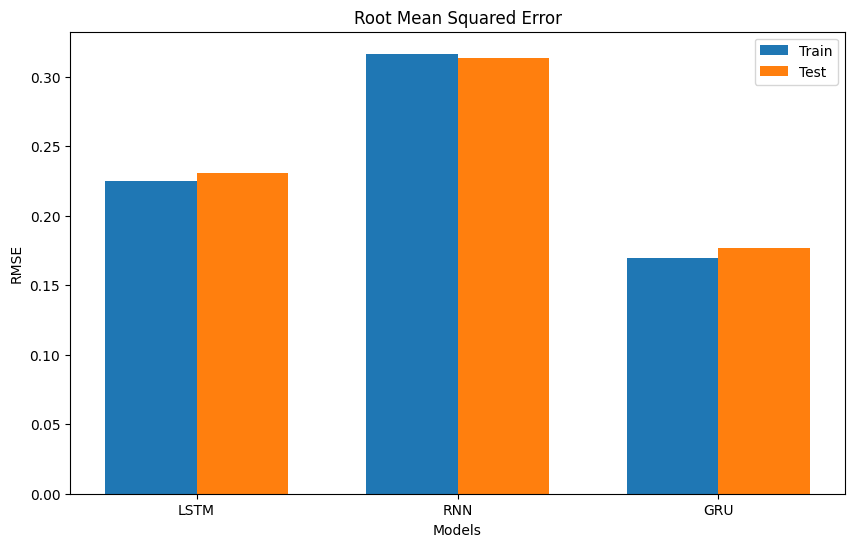

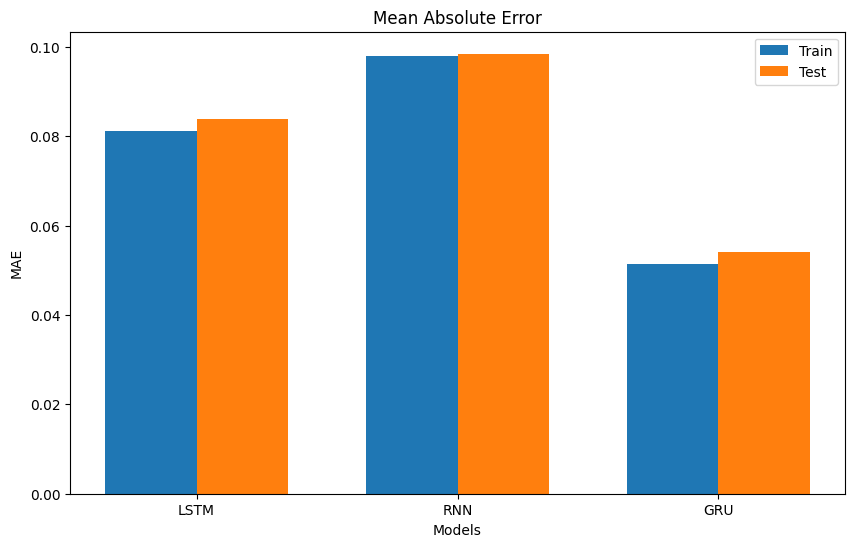

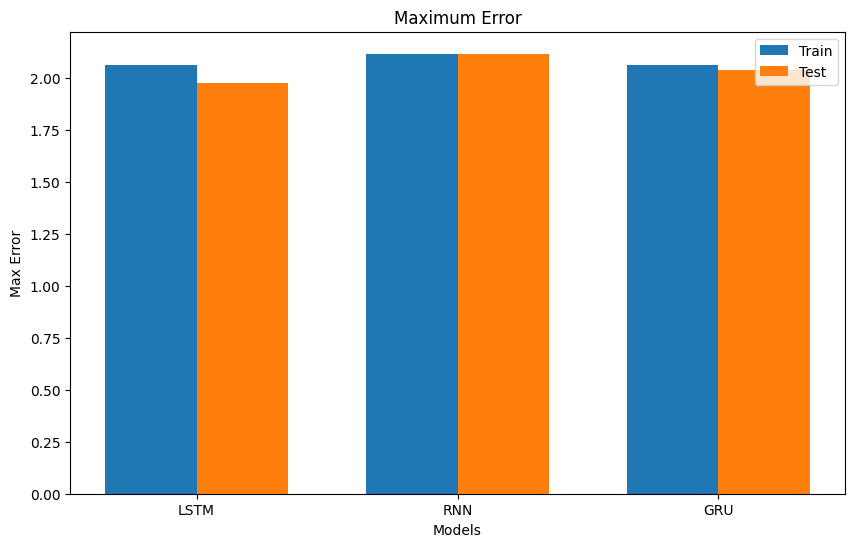

In [13]:
labels = ['LSTM', 'RNN', 'GRU']
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, train_rmse, width, label='Train')
plt.bar(x + width/2, test_rmse, width, label='Test')
plt.xlabel('Models')
plt.ylabel('RMSE')
plt.title('Root Mean Squared Error')
plt.xticks(x, labels)
plt.legend()
plt.savefig('rmse_plot.png')  # Save the figure as 'rmse_plot.png'
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, train_mae, width, label='Train')
plt.bar(x + width/2, test_mae, width, label='Test')
plt.xlabel('Models')
plt.ylabel('MAE')
plt.title('Mean Absolute Error')
plt.xticks(x, labels)
plt.legend()
plt.savefig('mae_plot.png')  # Save the figure as 'mae_plot.png'
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, train_max_error, width, label='Train')
plt.bar(x + width/2, test_max_error, width, label='Test')
plt.xlabel('Models')
plt.ylabel('Max Error')
plt.title('Maximum Error')
plt.xticks(x, labels)
plt.legend()
plt.savefig('max_error_plot.png')  # Save the figure as 'max_error_plot.png'
plt.show()


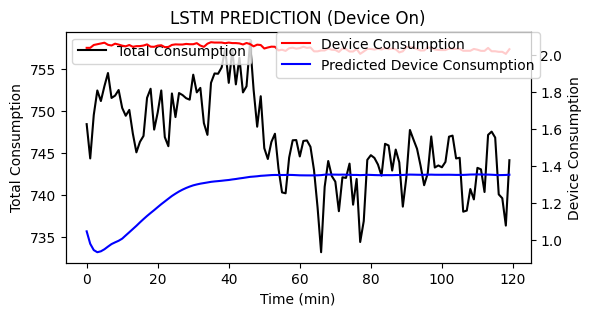

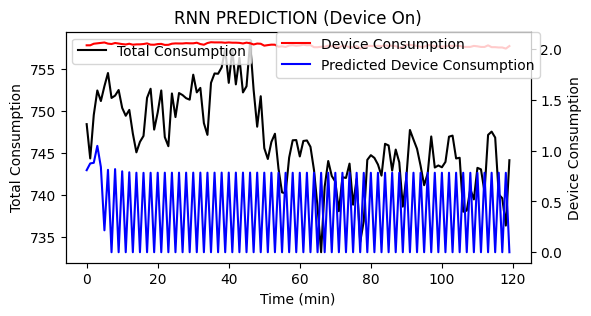

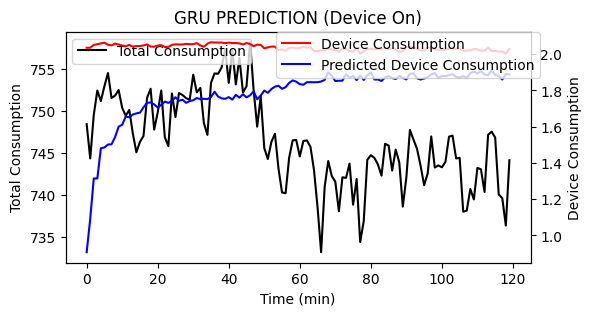

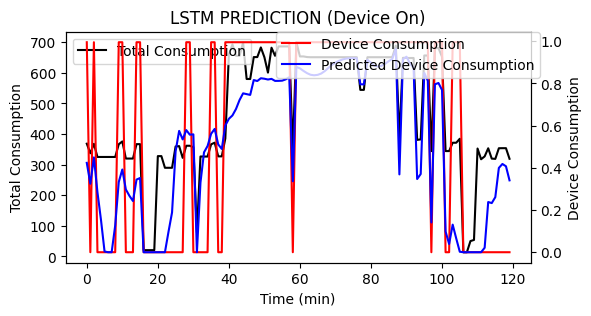

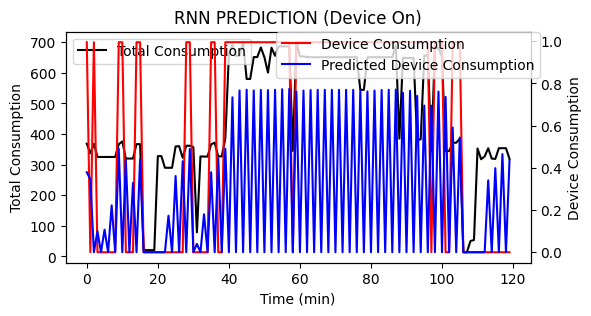

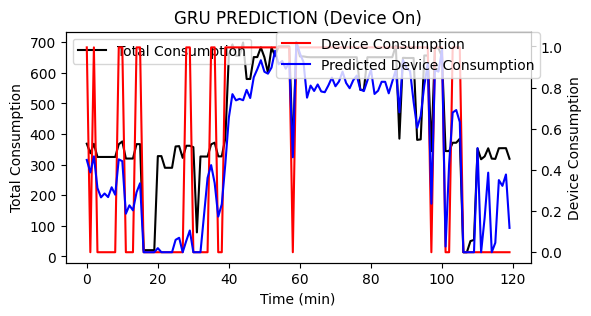

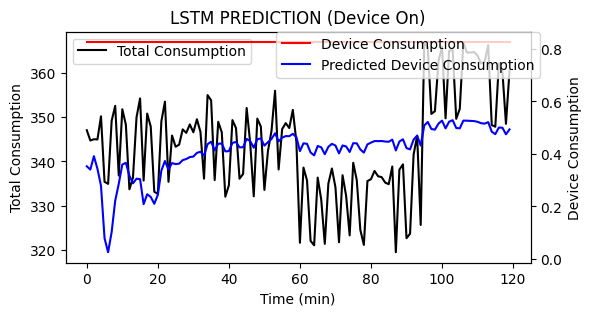

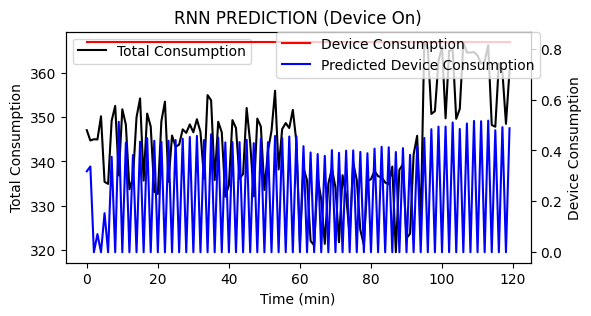

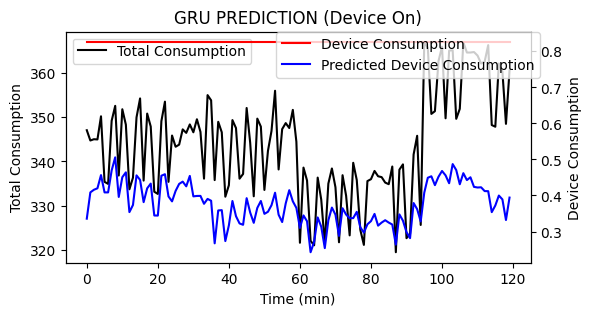

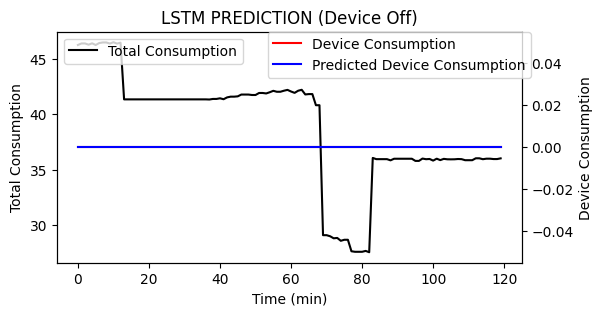

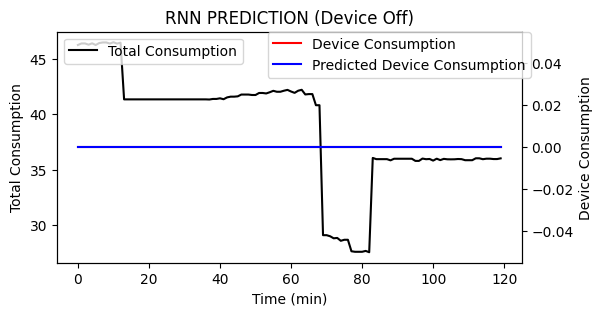

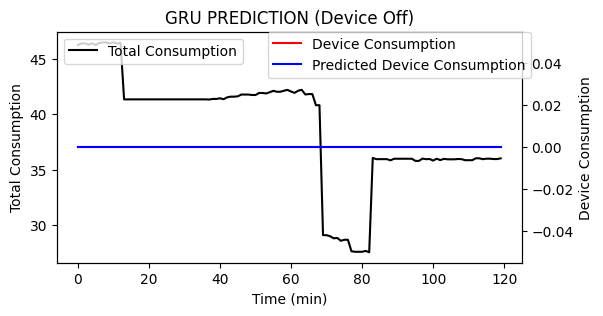

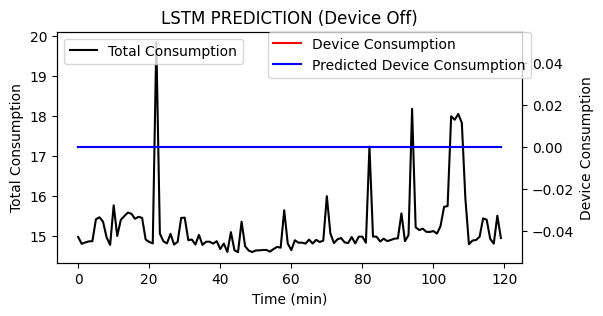

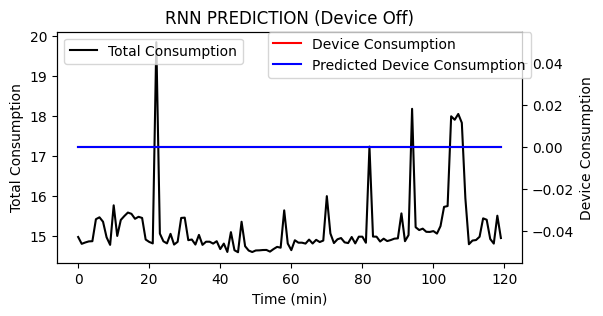

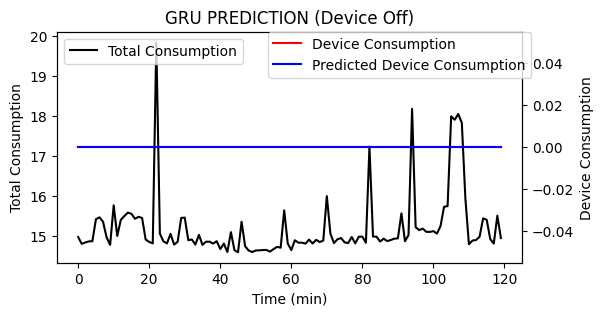

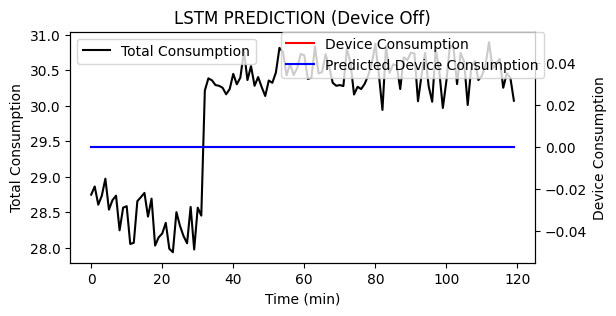

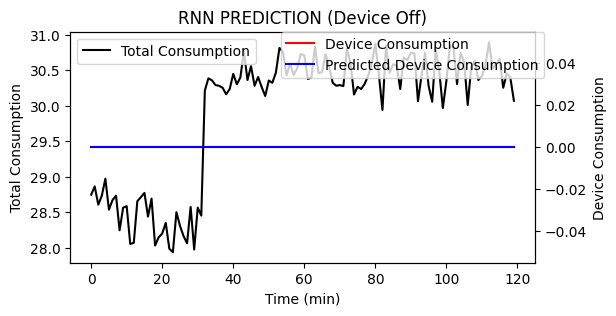

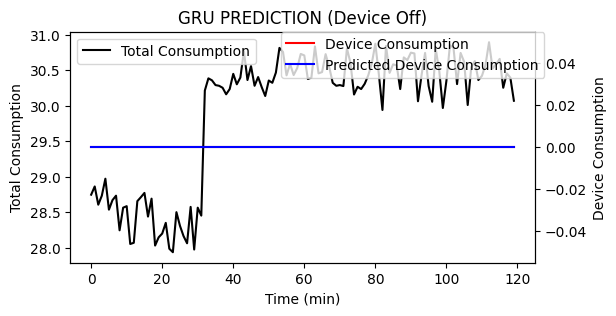

In [14]:
def plot_predicted(total_consumption, device_consumption, prediction, title_model, save_path):
    fig, ax1 = plt.subplots(figsize=(6, 3))
    ax2 = ax1.twinx()
    ax1.plot(total_consumption*1000, 'k-', label='Total Consumption')
    ax2.plot(device_consumption, 'r-', label='Device Consumption')
    ax2.plot(prediction, 'b-', label='Predicted Device Consumption')
    ax1.set_xlabel('Time (min)')
    ax1.set_ylabel('Total Consumption')
    ax2.set_ylabel('Device Consumption')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right', bbox_to_anchor=(1.02, 1), borderaxespad=0)
    ax1.set_title(title_model)

    # Save the figure
    plt.savefig(save_path)
    plt.show()

# Select lines where the device is on
device_on_indices = random.sample(list(np.where(test_output != 0)[0][2:]), 3)

# Select three random indices where the device is off
device_off_indices = random.sample(list(np.where(test_output == 0)[0][2:]), 3)



# Plot the graphs for lines where the device is on
for idx in device_on_indices:
    total_consumption = denormalize(test_input, max_agg)[idx]
    device_consumption = denormalize(test_output[idx], max_app)
    prediction_lstm = test_predictions_np[0][idx]
    prediction_rnn = test_predictions_np[1][idx]
    prediction_gru = test_predictions_np[2][idx]
    plot_predicted(total_consumption, device_consumption, prediction_lstm, f'LSTM PREDICTION (Device On)', f'on_plot_{idx}.png')
    plot_predicted(total_consumption, device_consumption, prediction_rnn, f'RNN PREDICTION (Device On)', f'on_plot_{idx}_rnn.png')
    plot_predicted(total_consumption, device_consumption, prediction_gru, f'GRU PREDICTION (Device On)', f'on_plot_{idx}_gru.png')

# Plot the graphs for lines where the device is off
for idx in device_off_indices:
    total_consumption = denormalize(test_input, max_agg)[idx]
    device_consumption = denormalize(test_output[idx], max_app)
    prediction_lstm = test_predictions_np[0][idx]
    prediction_rnn = test_predictions_np[1][idx]
    prediction_gru = test_predictions_np[2][idx]
    plot_predicted(total_consumption, device_consumption, prediction_lstm, f'LSTM PREDICTION (Device Off)', f'off_plot_{idx}.png')
    plot_predicted(total_consumption, device_consumption, prediction_rnn, f'RNN PREDICTION (Device Off)', f'off_plot_{idx}_rnn.png')
    plot_predicted(total_consumption, device_consumption, prediction_gru, f'GRU PREDICTION (Device Off)', f'off_plot_{idx}_gru.png')
